
# makemore: part 3

In [8]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
import time
import numpy as np
import random
import torch.nn as nn

device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
   device = "mps:0"

print(f"Running on {device}")


Running on mps:0


In [9]:

### build the dataset
block_size = 1
T = 128
end_char = '_' 
batch_size = 512

DATA = "words"
DATA = "shakespaere"

if DATA == "words": # read in all the words
    with open("data/names.txt", "r") as f:
        words = f.readlines()
    words = [word.strip() for word in words]
    #random.seed(42)
    random.shuffle(words)
    if end_char in "".join(words): exit(f"the character '{end_char}' is already in the vocabulary")
    text = "_".join(words)
elif DATA == "claire":
    ########### LOAD FROM DATASET
    from datasets import load_dataset
    import re
    import unicodedata

    # Login using e.g. `huggingface-cli login` to access this dataset
    ds = load_dataset("OpenLLM-France/Claire-Dialogue-French-0.1")

    dialogues = [el['text'] for el in ds['train']]

    # Refomating
    to_remove_c = "µ"
    dialogues = [el.replace(to_remove_c, "") for el in dialogues]
    dialogues = [re.sub(r'\[.*?\] ', '', el) for el in dialogues]
    dialogues = [unicodedata.normalize('NFKD', el).encode('ascii', 'ignore').decode('utf-8') for el in dialogues]

    print(dialogues[0][:100])
    print(len(dialogues), "dialogues loaded")

    start_word = 0

    #### SPLITS
    for i in range (1000):
        if sum(len(w) + 1 for w in dialogues[start_word:start_word+i]) > 2000_000:
            words = dialogues[start_word:start_word+i]
            print( i,"cut at", i + start_word, "dialogues with ", sum(len(w) + 1 for w in words), "characters")
            start_word += i
            break
elif DATA == "shakespaere":
    with open("data/tiny_shakespeare.txt", "r") as f:
        text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string


class DataLoader:
    def __init__(self, data):
        self.data = data.to(device)
        self.b_size = batch_size*T
        self.reset()

    def reset(self, b_size=None):
        if b_size is not None:
            self.b_size = b_size
        self.index = 0
        # create a random order for the indexes
        offset = random.randint(0, T)
        self.order = torch.randperm((len(self.data) - 1 - offset)//(self.b_size)).to(device)
        self.order = self.order * self.b_size + offset

    def get_batch(self):
        self.index += 1
        if self.index >= len(self.order):
            self.reset()
        indexes = self.order[self.index]
        if indexes + batch_size * T + 1 > len(self.data):
            self.reset()
        buf = self.data[indexes : indexes+batch_size*T+1]
        x = (buf[:-1]).view(batch_size, T) # inputs
        y = (buf[1:]).view(batch_size, T) # targets
        return x, y
    def get_batch_incremented(self, increment=0):
        idx = self.order[self.index] + increment
        if idx + batch_size * T + 1 > len(self.data):
            self.reset()
            idx = self.order[self.index] + increment
        buf = self.data[idx: idx+batch_size*T+1]
        x = (buf[:-1]).view(batch_size, T)
        y = (buf[1:]).view(batch_size, T)
        return x, y
    
    def get_batch_conseq(self, increment=0, max_increment=T):
        idx = self.order[self.index] # + increment
        if idx + batch_size * T + 1 > len(self.data) or increment + 1 >= max_increment:
            self.reset()
            idx = self.order[self.index] + increment
        buf = self.data[idx: idx+batch_size*T*max_increment +1]
        x = (buf[:-1]).view(batch_size, max_increment, T)[:,increment,:].contiguous() # contiguous is needed to avoid a bug in pytorch : it does not keep the stride
        y = (buf[1:]).view(batch_size, max_increment, T)[:,increment,:].contiguous()
        return x, y


# Train and test splits
data = torch.tensor(encode(text))#, dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
DLtr = DataLoader(data[:n])
DLte = DataLoader(data[n:])
print(f"vocab size {vocab_size} ,loaded {n} tokens : {n//batch_size} Time learning - {n//(batch_size * T)} batches of size {batch_size} and of length {T}")


# Forget about text variable in the notebook
del text
del data


# show first 5 examples
xb, yb = DLtr.get_batch()
print(f"ex : {decode(xb[0][:30].tolist())}")
for i in range(15,20):
    x = xb[:, i:i+block_size]
    y = yb[:, i+block_size - 1]
    #print(x, y)
    for b in range(2):
        print("X", i, ":", decode(x[b].tolist()), '-->', decode([y[b].tolist()]), end = "      \t\t")
    print()

for i in range(100):
    x, y = DLtr.get_batch()
    
    #print("X", i, ":", decode(x[0].tolist()), '-->', decode([y[0].tolist()]))
    assert x.shape == (batch_size,T), x.shape 
    assert y.shape == (batch_size,T), "mlkjqmlkdjf"
    assert (0 <= x).all() and  (x < vocab_size).all()
    assert (0 <= y).all() and (y < vocab_size).all()


DLtr.reset()


vocab size 65 ,loaded 1003854 tokens : 1960 Time learning - 15 batches of size 512 and of length 128
ex : :
But if your title to the cro
X 15 : i --> t      		X 15 :   --> l      		
X 16 : t --> l      		X 16 : l --> a      		
X 17 : l --> e      		X 17 : a --> t      		
X 18 : e -->        		X 18 : t --> e      		
X 19 :   --> t      		X 19 : e -->        		


# MODEL

In [ ]:
def myprint(t, name):
    print(f"{name:<10} : {tuple(t.shape)} ")#: {t[:1].tolist()}")


torch.set_default_dtype(torch.float32)


class MyModule(nn.Module):
    debug = False
    def states(self):return []
    def reset_state(self): return "default reset"
    def to(self, device):

        states =  self.states()
        for i in range(len(states)):
            if states[i] is None: continue # Ensure parameter exists
            states[i].data = states[i].data.to(device)  # Update the data in-place
        return super().to(device)



def call(mod, fn, *args, on_myself=True):
    out = []
    if on_myself:
        out =  [fn(mod, *args) if callable(fn) else f"{fn} is not callable"]
    for c in mod.children():
        out.extend(call(c, fn, *args))
    return out
        

# -----------------------------------------------------------------------------------------------

class Embedding(MyModule): # for each vocab index, look up the corresponding vector in a table
    def __init__(self, num_embeddings, embedding_dim):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((num_embeddings, embedding_dim)))
        self.IX = torch.zeros(32)
        
    def __call__(self, IX): # IX : (Batch, T(Time))
        self.IX = IX
        self.out = self.weight[IX] 
        return self.out # (B, T, C : channel)
    
    def backward(self, delta, x=None):
        IX = self.IX
        flattened_indices = IX.view(-1)  # Shape: (Batch * T)
        flattened_delta = delta.view(-1, delta.shape[-1])  # Shape: (Batch * T, Embedding_dim)
        self.weight.grad.index_add_(0, flattened_indices, flattened_delta)
        return self.weight.grad
    
# PYTORCHIFYING -----------
class Linear(MyModule):
    
    def __init__(self, fan_in, fan_out, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((fan_in, fan_out)) * (2/(fan_in+fan_out)) )
        self.bias = nn.Parameter(torch.zeros(fan_out)) if bias else None
    
    def __call__(self, x):
        self.x = x
        self.out = x @ self.weight
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T, fan_out)
        if x is None: x = self.x

        if grad:
            if self.bias is not None:
                self.bias.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

            x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D)
            delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
            self.weight.grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out)

        x_grad = delta @ self.weight.T # x grad : (batch, fan_in)
        return x_grad
    

class LinearBlocks(MyModule):
    def __init__(self, fan_in, fan_out, n_blocks=1, bias=True):
        super().__init__()
        # my wheights is (K, fan_in, fan_out) where K is the number of blocks
        self.weight = nn.Parameter(torch.randn((3, n_blocks, fan_in, fan_out)) * (4*2/(fan_in+fan_out)))
        self.bias = nn.Parameter(torch.zeros(fan_out)) if bias else None
        self.n_blocks = n_blocks
    
    def __call__(self, x): # x : (batch, ..., fan_in)
        self.x = x # x-> (B, ...., K, fan_in//K)
        x = x.reshape(*x.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_in//K)
        
        # Broadcast mat2 to match input's batch size
        #mat2_expanded = self.weight.unsqueeze(0).expand(batch_size, -1, -1, -1)  # Shape: (10, 5, 8, 6)
        #out = torch.matmul(x.unsqueeze(-2), mat2_expanded).squeeze(-2) # Perform batch matrix multiplication
        #out = torch.einsum('...bi,bio->...bo', x, self.weight) # (B, ..., K, fan_out//K)
        out = torch.einsum('...bi,sbio->...sbo', x, self.weight) # (B, ..., 2, K,  fan_out//K)

        #### Sum the two blocks but sum the first with the second of the one of the previous batch size
        
        # Shift and combine blocks efficiently using a single operation
        out[..., 0] = torch.roll(out[..., 0], shifts=-1, dims=-2)  # Shift blocks using roll
        out[..., -1] = torch.roll(out[..., -1], shifts=1, dims=-2)  # Shift blocks using roll
        out = out.sum(dim=-3)  # Sum across the blocks dimension
        #print(out.shape)    #10, 2, 64])

        
        self.out = out.reshape(*out.shape[:-2], -1) # (B, ..., fan_out)
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def backward(self, delta, x=None): # delta : (batch, ..., fan_out)
        if x is None: x = self.x

        if self.bias is not None:
            self.bias.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

        #x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D) (B + ..., fan_in)
        #delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
        #self.weight.grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out) 
        # (K, fan_in//K, fan_out//K)
        x = x.reshape(*x.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_in//K)
        delta = delta.view(*delta.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_out//K)
        #self.weight.grad += torch.einsum('...bi,...bo->bio', x, delta)#.view(self.weight.shape) # (K, fan_in//K, fan_out//K)

        delta_dubbled = torch.cat([torch.roll(delta, shifts=1, dims=-2).unsqueeze(-3), 
                                   delta.unsqueeze(-3) , 
                                   torch.roll(delta, shifts=-1, dims=-2).unsqueeze(-3)
                                   ], dim=-3) # (B, ..., 2, K, fan_out//K)
        #print(f"{delta_dubbled.shape=} {x.shape=} {self.weight.shape=}") 
        self.weight.grad += torch.einsum('...bi,...sbo->sbio', x, delta_dubbled)#.view(self.weight.shape) # (K, fan_in//K, fan_out//K)
        # delta_dubbled.shape=torch.Size([128, 2, 64, 64]) x.shape=torch.Size([128, 64, 64]) self.weight.shape=torch.Size([2, 64, 64, 64])

        #x_grad = delta @ self.weight.T # x grad : (... ,batch, fan_in)
        x_grad = torch.einsum('...sbo,sbio->...bi', delta_dubbled, self.weight) # (B, ..., K, fan_in//K)
        x_grad = x_grad.reshape(*x_grad.shape[:-2], -1) # (B, ..., fan_in)
        return x_grad

    
# -----------------------------------------------------------------------------------------------
class LayerNorm(MyModule):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps # for numerical stability
        self.dim = dim
        self.gamma = nn.Parameter(torch.ones(dim)) # (dim)
        self.beta = nn.Parameter(torch.zeros(dim)) # (dim)

    
    def __call__(self, x):
        self.compute_mms(x)
        self.out = self.gamma * (self.mu * self.sigma_inv) + self.beta
        return self.out
    
    def compute_mms(self, x):
        # calculate the forward pass
        self.xmean = x.mean(dim=-1, keepdim=True)
        self.mu = x - self.xmean
        xvar = x.var(dim=-1, unbiased=False, keepdim=True)
        self.sigma_inv = torch.sqrt(xvar + self.eps)**(-1) # normalize to unit variance
    
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T ..., dim)
        if x is not None:
            self.compute_mms(x)
        mu, sigma_inv, gamma = self.mu, self.sigma_inv, self.gamma

        if grad:
            self.beta.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))
            self.gamma.grad += (delta * mu * sigma_inv).sum(dim=tuple(range(delta.ndim - 1)))  # sum over batch : (dim)  
        
        # b:batch, h:hidden
        delta = (
            delta*gamma.unsqueeze(0) * sigma_inv
            - 1/self.dim * (torch.einsum('...h,h,...i->...', [delta, gamma, sigma_inv]).unsqueeze(-1) 
                 + mu * torch.einsum('...h,h,...h,...i->...', [delta, gamma, mu, sigma_inv**(3)]).unsqueeze(-1))
        )
        return delta # delta : (batch, dim)

  
# -----------------------------------------------------------------------------------------------

class Tanh(MyModule):
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def backward(self, delta, x=None, grad=True):
        if x is not None:
            self.__call__(x)
        return delta * (1 - self.out**2)

# -----------------------------------------------------------------------------------------------

class Flatten(MyModule):
    def __init__(self, input_shape, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.input_shape = input_shape

    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def backward(self, delta, x=None):
        return delta.view(self.input_shape)

# -----------------------------------------------------------------------------------------------

# Split and sum Module : split the input into the split_shape -> run the layers with the split input -> sum the output
class SplitSum(MyModule): # n > 1
    def __init__(self, layers, split_shape, save_x=False):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.split_shape = split_shape

    def __call__(self, x):  # (B,T, sum indim)
        split = x.split(self.split_shape, dim=-1)
        return sum(layer(s) for s, layer in zip(split, self.layers)) # (B,T, sum outdim)

    def backward(self, delta, x=None):
        if x is not None:
            split = x.split(self.split_shape, dim=-1)
            return torch.cat([layer.backward(delta, x=s) for s, layer in zip(split, self.layers)], dim=-1)

        return torch.cat([layer.backward(delta, x=x) for layer in self.layers], dim=-1)
    
# -----------------------------------------------------------------------------------------------

class Concat(MyModule):  # 1 -> n
    def __init__(self, layers, split_shape, save_x=False):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.split_shape = split_shape

    def __call__(self, x_cat): # (B,..., Sum indim)
        lst = [layer(x_cat) for layer in self.layers]
        return torch.cat(lst, dim=-1) # (B,T, Sum outdim)

    def backward(self, delta, x=None): # delta : (B,... , Sum outdim) -> (B,..., Sum indim
        ds = delta.split(self.split_shape, dim=-1)
        out =  [layer.backward(ds[i], x=x) for i, layer in enumerate(self.layers)]
        out = torch.sum(torch.stack(out), dim=0)
        return out 
    
# -----------------------------------------------------------------------------------------------
class Dropout(MyModule):
    def __init__(self, p=0.1):
        super().__init__()
        self.p = p
        self.reset_state()
    
    def reset_state(self):
        if self.training:
            self.mask = torch.rand(x.shape) > self.p
        else:
            self.mask = torch.ones(x.shape)
    def __call__(self, x):
        #self.mask = torch.rand(x.shape) > self.p
        return x * self.mask
    def backward(self, delta, x=None):
        return delta * self.mask

# -----------------------------------------------------------------------------------------------


# model class for looping over a layer
# this class is STATEFUL, it keeps track of the hidden state
class Loop(MyModule):
    def __init__(self, input_dim, output_dim, hidden_dim, n_blocks=1):
        super().__init__()

        # layers = [ Linear(input_dim + hidden_dim, hidden_dim + output_dim, bias=True), 
        #              LayerNorm(hidden_dim + output_dim), Tanh()]
        
        l_io = Linear(input_dim, input_dim, bias=True)
        l_ho = Linear(hidden_dim, output_dim, bias=False)
        l_oh = Linear(output_dim, hidden_dim, bias=True)
        #l_hh = Linear(hidden_dim, hidden_dim, bias=False)

        assert hidden_dim % n_blocks == 0, "hidden dim must be even"
        l_hh = LinearBlocks(hidden_dim//n_blocks, hidden_dim//n_blocks, n_blocks=n_blocks, bias=False)

        
        l_ih_o = SplitSum(layers=[l_io, l_ho], split_shape=(input_dim , hidden_dim))
        l_ih_h = SplitSum(layers=[l_oh, l_hh], split_shape=(output_dim, hidden_dim))

        layers = [Concat(layers=[ l_ih_o, l_ih_h], split_shape=(output_dim, hidden_dim)),
                    LayerNorm(hidden_dim + output_dim), Tanh()]
        
        ADD_DROPOUT = False
        if ADD_DROPOUT:
            layers = layers[:1] + [Dropout(0.1)] + layers[1:]
        
        self.layer = Sequential(layers=layers, save_x=True, input_dim=(input_dim + hidden_dim))

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim

        self.initial_h = nn.Parameter(torch.randn(1, hidden_dim) * 0.1)  # initialize hidden state to zeros

        self.no_direct_input = False
        self.no_loop = False
        self.device = None
        self.reset_state()

    def reset_state(self):
        # initialize hidden state : (different hidden state for each example in the batch)
        self.h = self.initial_h.expand(batch_size, -1) # (batch, hidden_dim)
        self.h_t = torch.zeros(batch_size, device=self.device) # (batch, 1)

    def __call__(self, x): # x : (batch, T, input_dim) and h : (1, hidden_dim)
        # LOOP over all the times
        y = torch.zeros(batch_size, T, self.output_dim, device=self.device)
        for t in range(T): # loop over all the times
            xt = x[:,t]
            out = self.layer(torch.cat([xt, self.h], dim=-1))
            yt, oh = out.split([self.output_dim, self.hidden_dim], dim=-1)
            self.h = oh # + self.h * 0.9 # residual connection
            if self.no_loop: self.h = torch.zeros_like(self.h)
            y[:,t] = yt
        self.h_t += T
        return y

    def backward(self, delta, x=None): # (B, T, out dim)
        #T = delta.shape[1]
        self.dgrad = torch.zeros(batch_size, self.hidden_dim, device=self.device)
        delta_out = torch.zeros(batch_size, T, self.input_dim, device=self.device)
        for t in range(T-1, -1, -1):
            delta_t = delta[:,t]
            out = self.layer.backward(torch.cat([delta_t, self.dgrad], dim=-1))
            delta_out_t, dgrad = out.split([self.input_dim, self.hidden_dim], dim=-1)
            self.dgrad = dgrad # + self.dgrad * 0.9 +  # because hi = hi-1 + f(hi-1, xi) => dldhi-1 = dldhi + dld(f(hi-1, xi))
            delta_out[:,t] = delta_out_t
        #if self.h_t - T == 0:
        #self.initial_h.grad += self.dgrad.sum(dim=0)
        # only where self.h_t - T == 0
        self.initial_h.grad += self.dgrad[self.h_t - T == 0].sum(dim=0)
        return delta_out

    
    def states(self):
        return [self.h, self.dgrad]

# -----------------------------------------------------------------------------------------------

class Sequential(MyModule):
    def __init__(self, layers, save_x=False, input_dim=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.input_dim = input_dim
        self.device = None

        self.update_BT_size()
    
    def reset_state(self):
        if self.save_x:
            self.t = 0

    def update_BT_size(self):
        if not self.save_x: return
        self.t = 0
        self.saved_x = []
        ## INPUT : (B,T,inp) -> (B,inp) -> (B, inp + hidden) 
        xt = torch.zeros(batch_size, self.input_dim, device=self.device)
        for l in self.layers:
            self.saved_x.append(torch.zeros(xt.shape[0], T, *xt.shape[1:], device=self.device))
            xt = l(xt)
    
    def __call__(self, x):
        for i, layer in enumerate(self.layers):
            if self.save_x and self.training:
                self.saved_x[i][:,self.t] = x
            x = layer(x)
        if self.save_x and self.training:
            self.t += 1
        return x
    
    def backward(self, delta, x = None, *args): 
        if self.save_x:
            self.t -= 1
            assert self.t >= 0, "t is negative"
        for i, layer in reversed(list(enumerate(self.layers))):
            #print(delta.device, ' brefore' , layer.__class__.__name__ )
            if self.save_x:
                x = self.saved_x[i][:,self.t]
            delta = layer.backward(delta, x=x, *args)
        return delta
    

  
# -----------------------------------------------------------------------------------------------
        
# class to wrap all the layers modules
class Model(Sequential):
    def __init__(self, layers):
        super().__init__(layers)
    
    def self_call(self, fn_name, *args):
        def function(x):
            if not hasattr(x, fn_name):
                return f"{x.__class__.__name__} don't have '{fn_name}'"
            method = getattr(x, fn_name)
            if not callable(method):
                return f"{fn_name} not callable on {x.__class__.__name__}"
            return method(*args), f"{fn_name} called on {x.__class__.__name__}"
            
        return call(self, function, on_myself=False)
    
    def reset_state(self):
        return self.self_call("reset_state")

    def set_var(self, var_name, value):
        return call(self, lambda x: value if setattr(x, var_name, value) is None else "not none")# if hasattr(x, var_name) else f"{var_name} is not an attribute")
    
    def get_var(self, var_name):
        return call(self, lambda x: getattr(x, var_name) if hasattr(x, var_name) else None)

def backward_cross_entropy(_y, _Yb): # cross entropy loss backward pass
    dy = F.softmax(_y, dim=-1)
    dy[torch.arange(_y.size(0)), _Yb] -= 1
    dy /= batch_size
    return dy

# model = Model([                # (B, T)
#     Embedding(vocab_size, n_embd),  # (B, T, C)
#     Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden, n_blocks=n_blocks), 
#     # loop of T : (B, t  C) -> (B, t, C_h)
#     Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
# ])



In [11]:
import torch

# Example dimensions
batch_size = 10
b = 5  # blocks
i = 8  # input size
o = 6  # output size

# Input tensors
input = torch.randn(batch_size, b, i)
mat2 = torch.randn(b, i, o, 2)

# # Broadcast mat2 to match input's batch size
# mat2_expanded = mat2.unsqueeze(0).expand(batch_size, -1, -1, -1)  # Shape: (10, 5, 8, 6)
# # Perform batch matrix multiplication
# res_matmul = torch.matmul(input.unsqueeze(-2), mat2_expanded).squeeze(-2)

# Verify correctness
res_einsum = torch.einsum('...bi,bios->...bos', input, mat2)
# assert torch.allclose(res_einsum, res_matmul), "Results differ!"

print(f"{mat2.shape}")# {mat2_expanded.shape} {res_matmul.shape}")

print("Optimized implementation works correctly!")

torch.Size([5, 8, 6, 2])
Optimized implementation works correctly!


In [12]:

n_embd = 256 # the dimensionality of the character embedding vectors
n_out_hidden = n_embd

n_blocks = 256
lin_block_size = 64
n_hidden = n_blocks * lin_block_size #256 # the number of neurons in the hidden layer of the MLP

#n_hidden = 4096 - n_embd
total_steps, train_index, train_time = 0, 0, 0
#lossi = [] # store loss values
class Store: # class to store values ( lossi, batch_time, train_time)
    # store the values as a dictionary of lists
    def __init__(self):
        self.store = {}
    def add(self, idx, **kwargs):
        for k, v in kwargs.items():
            if k not in self.store:
                self.store[k] = [None] * idx
        for k, lst in self.store.items():
            if k in kwargs:
                if idx < len(lst):
                    lst[idx] = kwargs[k]
                else:
                    lst.append(kwargs[k])
            else:
                if idx >= len(lst):
                    lst.append(None)
    def __getitem__(self, key):
        return self.store[key]
    def average(self, n_elements, key):
        last_elements = self.store[key][-n_elements:]
        n_elements = max(1, len(last_elements) - last_elements.count(None))
        if n_elements == 0: return 0
        return sum(el for el in last_elements if el is not None) / n_elements
    
    def averages(self, n_elements, *keys):
        return [self.average(n_elements, key) for key in keys]
        
store = Store()


CMP = False
torch.set_grad_enabled(CMP)
torch.manual_seed(42)

LOOP = True

if LOOP:
    model = Model([                # (B, T)
        Embedding(vocab_size, n_embd),  # (B, T, C)
        Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden, n_blocks=n_blocks), 
        # loop of T : (B, t  C) -> (B, t, C_h)
        Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
    ])
# else:
#     model = Model([
#         Embedding(vocab_size, n_embd), 
#         Linear(n_embd , n_hidden, bias=True), LayerNorm(n_hidden), Tanh(),  
#         Linear(n_hidden, vocab_size)
#     ])
# with torch.no_grad():
#     last layer: make less confident
#     model.layers[-1].weight *= 0.1
#     model.layers[-1].bias *= 0.1
#   all other layers: apply gain
#   for layer in model.layers[:-1]:
#     if isinstance(layer, Linear):
#       layer.weight *= 0.5 #* 5/3

for name, p in model.named_parameters():
    if 'weight' in name:
        p.data *= 0.1

model.set_var("device", device)
model = model.to(device)

def show_states(model):
    states = model.get_var("h")
    for s in states:
        if s is not None:
            # # scatter with a different color for each example in the batch
            # for i in range(s.shape[0]):
            #     plt.scatter(range(s.shape[1]), s[i].detach().cpu().numpy(), label=f'Example {i}', cmap='viridis', alpha=0.5, s=10)

            values = s.detach().cpu().numpy()#[:, :100]
            mean = values.mean(axis=0)
            std = values.std(axis=0)

            #for i in range(values.shape[0]):
            #    plt.scatter(range(values.shape[-1]), values[i], s=1)


            #plt.plot(mean)
            plt.scatter(range(values.shape[-1]), mean, s=1)
            plt.show()

            # print the hash value
            print(f"mean : {mean.mean()} std : {std.mean()} hash : {hash(tuple(mean))}")


if CMP:
    for p in model.parameters():
        p.requires_grad = True

print(sum(p.numel() for p in model.parameters())/1e6, 'M parameters')
print(f"Total parameters : {sum(p.nelement() for p in model.parameters())}")
#print(model)
for name, l in model.named_modules():
    print(f"{l.__class__.__name__:<30} : {name:<50} :   size : {sum(p.nelement() for p in l.parameters())} ({l.device if hasattr(l, 'device') else 'no device'})")
for name, p in model.named_parameters():
    print(f"{name:<50} :  {str(tuple(p.shape)):<20}  size : {p.nelement():<10}  ({p.device})")



11.699521 M parameters
Total parameters : 11699521
Model                          :                                                    :   size : 11699521 (mps:0)
ModuleList                     : layers                                             :   size : 11699521 (mps:0)
Embedding                      : layers.0                                           :   size : 16640 (mps:0)
Loop                           : layers.1                                           :   size : 11666176 (mps:0)
Sequential                     : layers.1.layer                                     :   size : 11649792 (mps:0)
ModuleList                     : layers.1.layer.layers                              :   size : 11649792 (mps:0)
Concat                         : layers.1.layer.layers.0                            :   size : 11616512 (mps:0)
ModuleList                     : layers.1.layer.layers.0.layers                     :   size : 11616512 (mps:0)
SplitSum                       : layers.1.layer.layers.0

In [13]:
# training the model
steps = 1_0000
batch_size = 128
T = 128




#0,000000012207031
print_step = 10 #steps//10

model.reset_state()

model.train()
model.set_var("no_direct_input", False)
model.set_var("no_loop", False)
model.self_call("update_BT_size")

for p in model.parameters():
    p.grad = torch.zeros_like(p)

steps -= (total_steps + steps) % steps
steps = max(10, steps)
total_steps += steps
start_time = time.time()

base_lr = 1e-4
#### ADAM optimizer
optimizer = torch.optim.Adam(model.parameters(), 
                                lr=base_lr, # the learning rate
                                betas=(0.9, 0.999),  # beta : coefficients used for computing running averages of gradient and its square
                                eps=1e-8,            # term added to the denominator to improve numerical stability
                                weight_decay=1e-2,     # weight decay  : factor to decay the weights to avoid overfitting
                            amsgrad=False) # whether to use the AMSGrad variant of this algorithm
### To use the optimizer : 



print(f"training on {device} for {steps} steps of {batch_size} batches of {T} tokens -- {steps * (batch_size * T)} tokens -- {steps//(batch_size * T)} epochs")

incr = 0
max_incr = 0
#DLtr.reset(batch_size * T + max_incr * T)
DLtr.reset(batch_size * T)
if max_incr != 0:
    DLtr.reset(batch_size * T * max_incr)
for i in range(steps):
    # minibatch construct : sample a random subset of the data
    # Xb, targets = DLtr.get_batch() # (B, T)
    # model.reset_state()
    
    #### TRAIN with the folow up
    incr += 1
    if max_incr == 0:
        incr = 0
        Xb, targets = DLtr.get_batch()
        model.reset_state()
    else:
        if incr >= max_incr:
            incr = 0
            model.reset_state()
        Xb, targets = DLtr.get_batch_conseq(increment=incr, max_increment=max_incr)
        def increment_state(layer):
            if not layer.__class__.__name__ == "Loop":
                return "not a loop"
            #layer.h_t = torch.cat([layer.h_t[1:], torch.zeros(1, device=layer.device)], dim=0)
            #layer.h = torch.cat([layer.h[1:], layer.initial_h.expand(1, -1)], dim=0)
        out = call(model, increment_state)
    
    # forward pass
    y = model(Xb) # y : (B, T, Vocab size)
    
    targets = targets.view(-1) # (B * T)
    y = y.view(-1, vocab_size) # (B * T, vacab)vocab_size
    loss = F.cross_entropy(y, targets) # y needs to be (B * T, C)


    ############# backward pass ################
    # zero all the gradients in the model
    for p in model.parameters():
        p.grad.zero_()

    dy = backward_cross_entropy(y, targets)
    dy = dy.view(batch_size, T, -1) # (B, T, C)
    delta = model.backward(dy)

    # # Backward pass
    # optimizer.zero_grad()
    # loss.backward()
    # optimizer.step()


    # if CMP: 
    #     # zero all the gradients in the model
    #     for p in model.parameters():
    #         p.grad = None
    #     y.retain_grad() 
    #     loss.backward() # backpropagate the error
    #     cmp("dy", dy, y.grad, only_errors=True)
    ##################################################

    # update
    lr = base_lr# if train_index < 3000 else base_lr / 10 # step learning rate decay    
    total_grad_norm = 0
    for name, p in model.named_parameters():
        # Prevent gradient explosion
        # if p.grad.norm() > 100:
        #     print(f"Gradient explosion in {name} : {p.grad.norm().item()}")
        #     p.grad = p.grad / p.grad.norm() * 100
        
        v = p.grad.sum() / p.grad.nelement()

        if v > 1e-2:
            print(f"Gradient explosion in {name} : {v} ({p.grad.norm().item()})")
            p.grad = p.grad / v * 1e-2
        
        #print(f"{name} : {p.grad.norm().item()}")
        total_grad_norm += p.grad.norm().item()

        p.data += -lr * p.grad
        #if CMP: cmp(name, p.grad, g, only_errors=True)


    # track stats
    #lossi.append(loss.log10().item())
    #print(f"{i}/{steps} : {loss.item():.4f} - {10**loss.item():.4f}  ({time.time() - start_time:.0f}s)", end = "\r")
    
    store.add(train_index, loss=loss.log10().item(), lr=lr, batch_size=batch_size, T=T,  max_incr=max_incr, total_grad_norm=total_grad_norm)
    if (i+1) % (print_step) == 0: # print every once in a while
        dt = time.time() - start_time
        start_time = time.time()
        train_time += dt
        processed_tokens = print_step * batch_size * T
        # losses = store["loss"][-print_step:]
        # avg_loss = sum(losses) / len(losses)
        avg_loss, avg_grad_norm  = store.averages(print_step, "loss", "total_grad_norm")
        print(f'{train_index:7d}/{total_steps:7d}:  {avg_loss:.4f} - {10**avg_loss:.4f}  ({train_time:.0f}s : +{int(dt):3d}s)  {processed_tokens / (dt*1e3):.0f} k tok/s  {print_step *60 / (dt):.0f} step/min   avg grad norm : {avg_grad_norm:.4f}  lr : {lr:.0e}  max_incr : {max_incr}  ')#, end = "\r")
        store.add(train_index, dt=dt, train_time=train_time)

    train_index += 1

print(f"Training time: {train_time:.0f} seconds")
total_steps = train_index

training on mps:0 for 10000 steps of 128 batches of 128 tokens -- 163840000 tokens -- 0 epochs
      9/  10000:  0.5977 - 3.9603  (20s : + 19s)  8 k tok/s  31 step/min   avg grad norm : 1376.4449  lr : 1e-04  max_incr : 0  
     19/  10000:  0.5465 - 3.5198  (39s : + 19s)  9 k tok/s  31 step/min   avg grad norm : 261.8458  lr : 1e-04  max_incr : 0  
     29/  10000:  0.5324 - 3.4074  (58s : + 19s)  9 k tok/s  31 step/min   avg grad norm : 126.7741  lr : 1e-04  max_incr : 0  
     39/  10000:  0.5306 - 3.3935  (77s : + 19s)  8 k tok/s  31 step/min   avg grad norm : 89.0163  lr : 1e-04  max_incr : 0  
     49/  10000:  0.5236 - 3.3387  (97s : + 19s)  9 k tok/s  31 step/min   avg grad norm : 75.3711  lr : 1e-04  max_incr : 0  
     59/  10000:  0.5241 - 3.3426  (116s : + 19s)  9 k tok/s  31 step/min   avg grad norm : 62.0674  lr : 1e-04  max_incr : 0  
     69/  10000:  0.5219 - 3.3260  (135s : + 19s)  9 k tok/s  31 step/min   avg grad norm : 55.1645  lr : 1e-04  max_incr : 0  
     79/  

KeyboardInterrupt: 

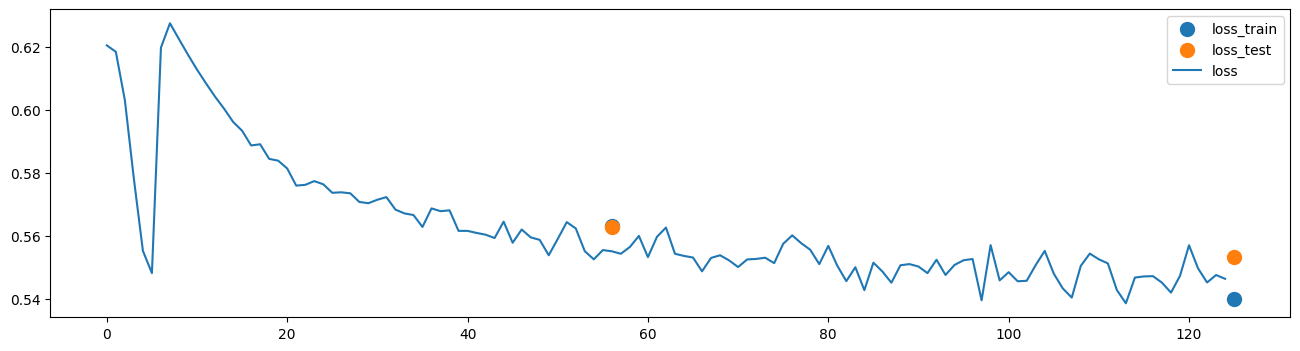

/var/folders/_s/ysm78cds61z2q1t03gj_hj7w0000gn/T/ipykernel_36438/3096168585.py:86: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/ReduceOps.cpp:1823.)
  std = tens[-len(tens)//2:].std().item()


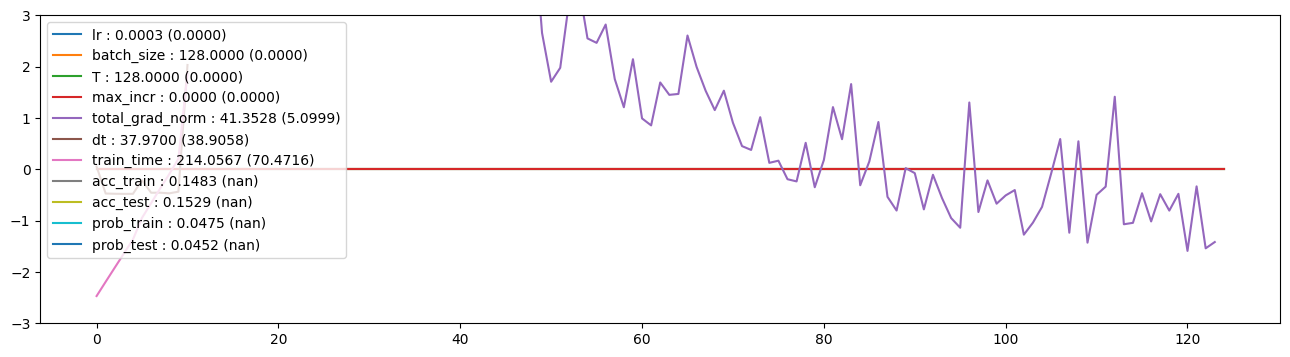

# 125 steps, 346s (Batch: 128, T: 128 , lr: 0.0003, hidden: 16384, n_blocks: 256) : 3.57719349861145
# train loss : 3.4667   	 acc 14.8% 	 prob 4.8%     (log:0.5399148364479548)
# test  loss : 3.5772  	 acc 15.3% 	 prob 4.5%


In [91]:
# printing the loss
total_steps = train_index
model.eval()
T = 128
batch_size = 128
model.self_call("update_BT_size")


#  Evaluate the model
@torch.no_grad()  # Disable gradient tracking
def split_loss_and_accuracy(DL, n_iteration=1):
    avg_loss = 0
    correct_predictions = 0
    total_predictions = 0
    avg_correct_prob = 0
    
    for i in range(n_iteration):
        # Get the input and target sequences
        x, y = DL.get_batch()  # Fetch data batch
        model.reset_state()

        # Forward pass through the model
        x = model(x)  # Output logits
        x = x.view(-1, vocab_size)  # Reshape logits for loss computation
        y = y.view(-1)  # Flatten targets

        # Compute loss
        avg_loss += F.cross_entropy(x, y, reduction='mean').item()

        # Compute accuracy
        predictions = torch.argmax(x, dim=1)  # Predicted class indices
        correct_predictions += (predictions == y).sum().item()  # Count correct predictions
        total_predictions += y.size(0)  # Count total predictions
        
        proba = F.softmax(x, dim=1)
        correct_probs = proba[torch.arange(y.size(0)), y]  # Correct class probabilities
        avg_correct_prob += correct_probs.mean().item()

    avg_loss /= n_iteration  # Average the loss over iterations
    accuracy = correct_predictions / total_predictions  # Compute accuracy
    avg_correct_prob /= n_iteration
    return avg_loss, accuracy, avg_correct_prob


trloss, tracc, tr_prob = split_loss_and_accuracy(DLtr)
teloss, teacc, te_prob = split_loss_and_accuracy(DLte)

store.add(train_index, loss_train=np.log10(trloss), loss_test=np.log10(teloss), acc_train=tracc, acc_test=teacc, prob_train=tr_prob, prob_test=te_prob)



spliter = 10**int(np.log10(train_index)-2)
spliter = 1

plt.figure(figsize=(16, 4))
keys = list(store.store.keys())
keys = ['loss_train', 'loss_test', 'loss'] + [k for k in keys if k not in ['loss_train', 'loss_test', 'loss']]
for k in keys:
    lst = store[k]
    if k == "loss":
        #averaged_loss = torch.tensor(lst).view(-1, spliter).mean(1)
        # support None
        averaged_loss = [sum([l for l in lst[i:i+spliter] if l is not None]) / sum([1 for l in lst[i:i+spliter] if l is not None])
                          if sum([1 for l in lst[i:i+spliter] if l is not None]) != 0 else None
            for i in range(0, len(lst), spliter)]

        plt.plot(range(0, len(lst), spliter), averaged_loss, label=k)
        plt.legend()
        plt.show()
        plt.figure(figsize=(16, 4))
        continue
    if k.startswith("loss"):
        plt.scatter(range(len(lst)), lst, label=k, s=100)
        continue
    # if k == 'lr':
    #     plt.plot([l * 10 / min(lst) for l in lst], label=k + " *"+ str(int(10/min(lst))))
    #     continue
    
    # lst to put between 0 and 1
    #div = max([el for el in lst if el is not None] + [0.0001]) 
    lst = [el for el in lst  if el is not None and el != np.inf]
    indexes = [i for i, el in enumerate(lst)]
    tens = torch.tensor(lst, dtype=torch.float)
    ## calculate the mean and std over the last 20% of the values
    mean = tens[-len(tens)//2:].mean().item()
    std = tens[-len(tens)//2:].std().item()
    # std = tens.std().item()
    lst_scaled = [(l - mean) / (1e-9 + std) 
                   if l is not None else l for l in lst]
    plt.plot(indexes, lst_scaled, label=k + f" : {mean:.4f} ({std:.4f})")

plt.ylim(-3, 3)
plt.legend()
plt.show()


print(f"# {total_steps} steps, {train_time:.0f}s (Batch: {batch_size}, T: {T} , lr: {base_lr}, hidden: {n_hidden}, n_blocks: {n_blocks}) : {teloss}")
print(f"# train loss : {trloss:.4f}   \t acc {tracc * 100:.1f}% \t prob {tr_prob * 100:.1f}%     (log:{np.log10(trloss)})")
print(f"# test  loss : {teloss:0.4f}  \t acc {teacc * 100:.1f}% \t prob {te_prob * 100:.1f}%")

if teloss - trloss > 0.15:
    print(f"\033[91mModel is overfitting : {teloss - trloss}\033[0m")



#plt.plot(torch.tensor(store['loss'][:train_index//spliter*spliter]).view(-1, spliter).mean(1));


# 1 letter

# LOOP  
# # 13000 steps, 708s (Batch: 32, block: 1, lr: 0.01, hidden: 64) : 2.0660481452941895
# train loss : 2.0372254848480225      (log:0.30903910038242466)  
#  test  loss : 2.0660
# 2000 steps, 420s (Batch: 32, block: 1, lr: 0.001, hidden: 256) : 2.0285587986310323
#  train loss : 1.9258   	 acc 45.7% 	 prob 29.6%     (log:0.2846129310450921)
# test  loss : 2.0286  	 acc 42.0% 	 prob 28.2%
## ON shakespaere
# 5700 steps, 972s (Batch: 64, block: 1, lr: 1e-05, hidden: 256) : 1.9928557395935058
# train loss : 1.8798   	 acc 47.4% 	 prob 30.6%     (log:0.27412079568294734)
# test  loss : 1.9929  	 acc 43.3% 	 prob 28.8%

# 6000 steps, 1769s (Batch: 256, block: 1, lr: 1e-05, hidden: 2048) : 2.0588078180948894
# train loss : 1.9326   	 acc 47.1% 	 prob 29.2%     (log:0.2861399360175299)
# test  loss : 2.0588  	 acc 42.9% 	 prob 27.3%

# LOOP WITH 
# 1377 steps, 685s (Batch: 32, block: 1, lr: 3e-05, hidden: 1920) : 1.834254789352417
# train loss : 1.7270   	 acc 50.4% 	 prob 33.6%     (log:0.23729749326630098)
# test  loss : 1.8343  	 acc 46.3% 	 prob 31.8%

# 3957 steps, 2438s (Batch: 64, block: 1, lr: 0.0001, hidden: 3968) : 1.7648982763290406
# train loss : 1.5607   	 acc 54.3% 	 prob 38.9%     (log:0.19330884479349006)
# test  loss : 1.7649  	 acc 48.5% 	 prob 35.2%

# linear block with 1 link
# 687 steps, 453s (Batch: 64, block: 1, lr: 0.0003, hidden: 1024) : 1.825671124458313
# 878 steps, 864s (Batch: 64, block: 1, lr: 0.0003, hidden: 1024) : 1.8196477174758912
# train loss : 1.6379   	 acc 51.8% 	 prob 35.9%     (log:0.21429878582449854)
# test  loss : 1.8257  	 acc 45.9% 	 prob 32.3%

# Loop 128 - 128 blocks
# 1725 steps, 2394s (Batch: 16, block: 1, lr: 0.01  , hidden: 16384) : 1.758005690574646
# 1904 steps, 2806s (Batch: 16, block: 1, lr: 0.0003, hidden: 16384) : 1.7028622388839723
# 2416 steps, 4029s (Batch: 16, block: 1, lr: 0.0001, hidden: 16384) : 1.679772400856018


# 256 - 64 blocks forward backward
# 403 steps, 834s (Batch: 128, block: 1, lr: 0.001, hidden: 16384) : 1.8830100536346435
# 1616 steps, 4890s (Batch: 128, T: 128 , lr: 0.001, hidden: 16384, n_blocks: 256) : 1.6852755308151246
# 2293 steps, 7506s (Batch: 128, T: 128 , lr: 0.0003, hidden: 16384, n_blocks: 256) : 1.6311242818832397


torch.Size([256, 256])


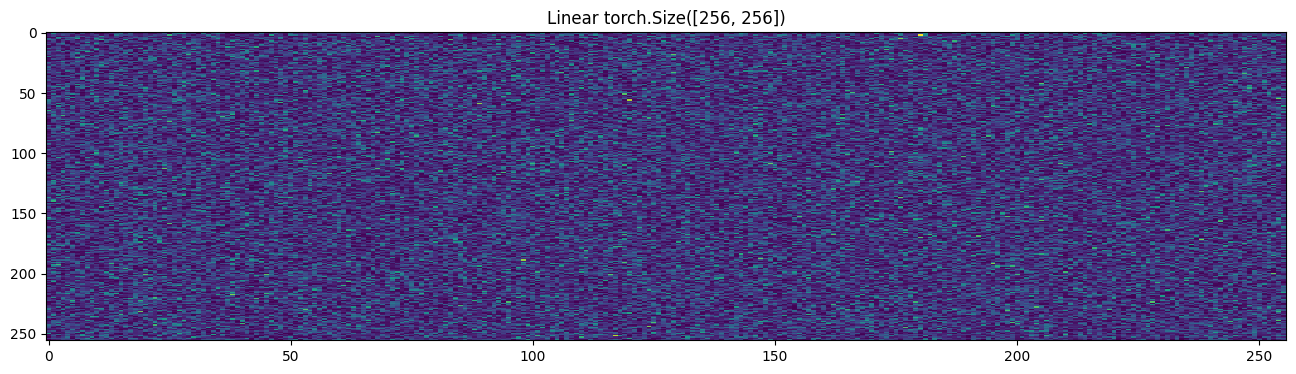

torch.Size([16384, 256])


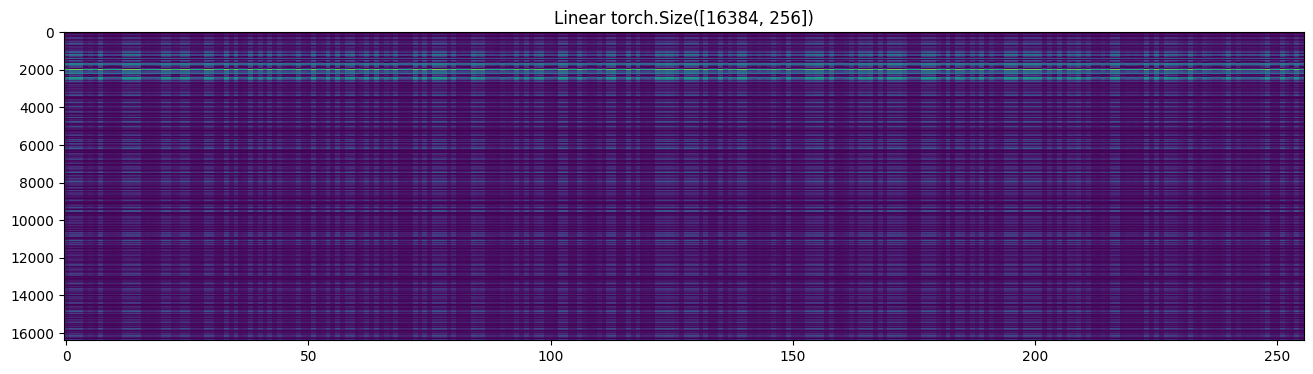

torch.Size([256, 16384])


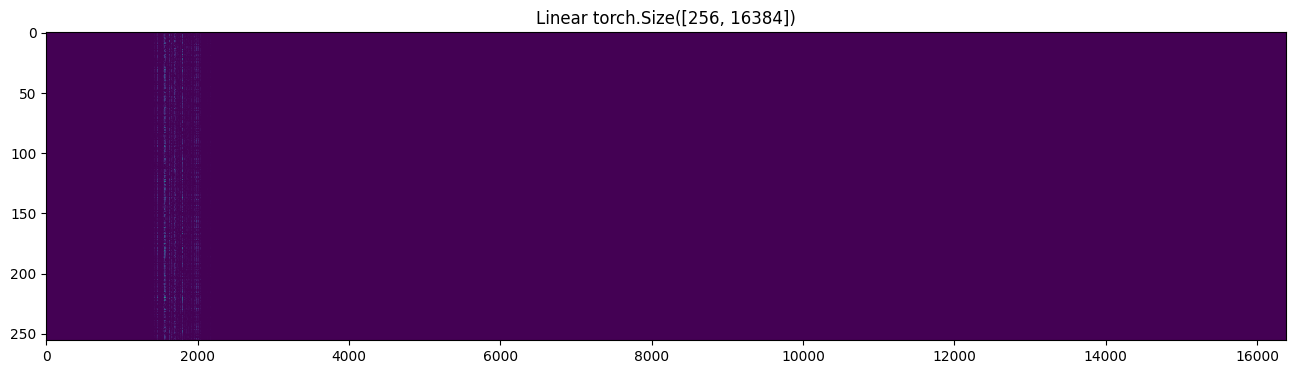

torch.Size([64, 49152])


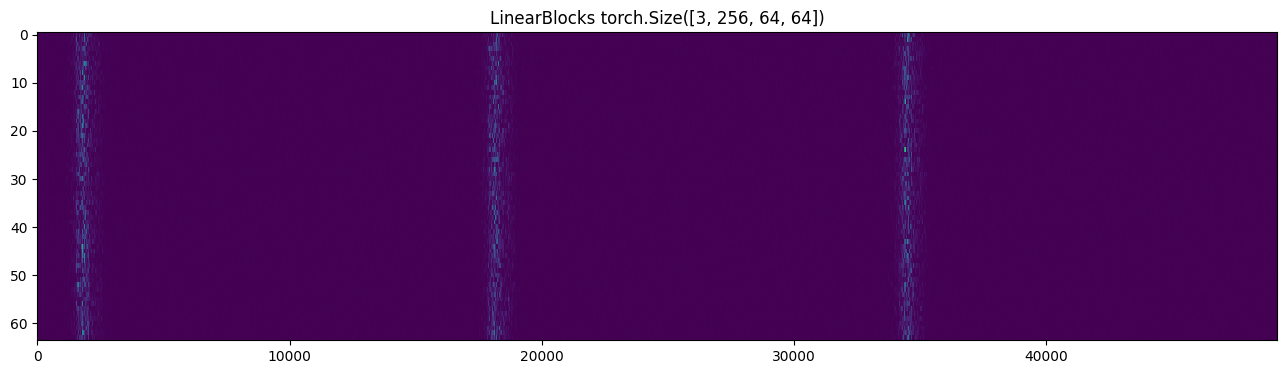

abs mean : 0.0003188747796230018 abs std : 0.0002410096349194646, 100.0 % non zero weights  20% threshold: 0.00010098776692757383
abs mean : 708500652032.0 abs std : 741641158656.0, 100.0 % non zero weights  20% threshold: 180655154790.40005
abs mean : 46429573742592.0 abs std : 454849720221696.0, 100.0 % non zero weights  20% threshold: 1395170292531.2002
abs mean : 0.01291373185813427 abs std : 0.047220081090927124, 100.0 % non zero weights  20% threshold: 0.0017623551888391376


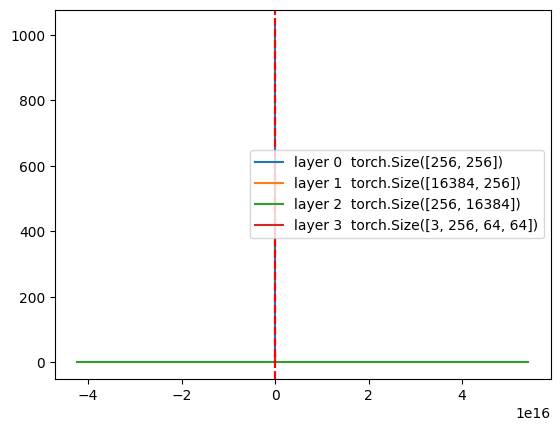

In [92]:

def find_loop(layer):
    if layer.__class__.__name__ == "SplitSum":
        for l in layer.layers:
            global layers
            if l.__class__.__name__ == "Linear" or l.__class__.__name__ == "LinearBlocks":
                layers.append(l)

    if layer.__class__.__name__ == "Loop":
        if layer.layer.layers[0].__class__.__name__ == "Linear":
            layers.append(layer.layer.layers[0])

layers = []
call(model, find_loop)
# for layer in layers:
#     threshold = np.percentile(layer.weight.abs().cpu().numpy(), 30)
#     layer.weight.data[layer.weight.abs() < threshold] /= 10


for layer in layers:
    loop_w = layer.weight
    if loop_w.dim() == 4:
        loop_w = loop_w.view(-1, loop_w.shape[-1]).T
    if loop_w.dim() > 2:
        loop_w = loop_w.view(-1, loop_w.shape[-1])

    print(loop_w.shape)
    threshold = np.percentile(loop_w.abs().cpu().numpy(), 30)
    plt.figure(figsize=(16, 4))
    plt.imshow(loop_w.abs().cpu().numpy(), aspect='auto', interpolation='none') #  > threshold
    plt.title(f"{layer.__class__.__name__} {layer.weight.shape}")
    plt.show()

for layer in layers:
    w = layer.weight
    threshold = np.percentile(w.abs().cpu().numpy(), 20)
    print(f"abs mean : {w.abs().mean().item()} abs std : {w.abs().std().item()}, {w.count_nonzero()/ w.nelement() *100} % non zero weights  20% threshold: {threshold}")
    #plt.plot(np.histogram(w.flatten().cpu().numpy(), bins=200)[0]) 
    # plot the histogram with the correct x axis
    h = np.histogram(w.flatten().cpu().numpy(), bins=200, density=True)
    plt.plot(h[1][:-1], h[0])

plt.legend([f"layer {i}  {l.weight.shape}" for i, l in enumerate(layers)])

w = torch.cat([layer.weight.flatten() for layer in layers], dim=0)
threshold = np.percentile(w.abs().cpu().numpy(), 20)
plt.axvline(x=-threshold, color='r', linestyle='--')
plt.axvline(x=threshold, color='r', linestyle='--')




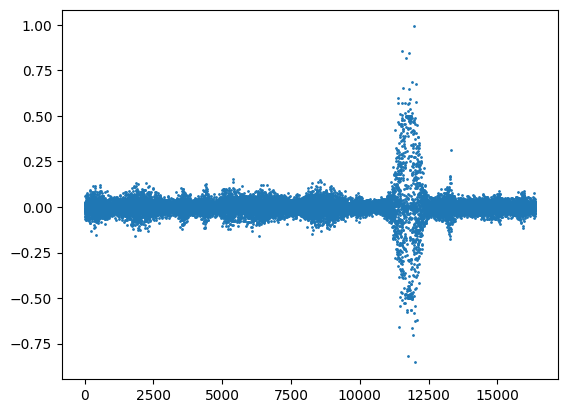

mean : 0.0006227779667824507 std : 0.09478788077831268 hash : 2523877859959297491
1001 tokens : all I orot ontart of me, tETTAs now th th,
Lj:'M
ET:
LUS:
The now,
OMPEPMENrich mansive thenty i's ber sones
Will precou wiken the pow hiodful kincor to hein wer couthous nomevicguep:
CESTEE:
Yead hanfe tour hen rladPearin.
Uvon to ter am, it escquek lightheicell Weband hast of of migh sentwant?

bat enwaslest
IGRONZULINLIEGNS:
Name tay lor vall.
'tx gre,
st:
Hen,

CBENCK:
N berle.
GlLo wie.
Higt Sayblavesulte som
HerTI coy

zerich, fresuccelsb: his; whaclen, Awnd wees,
Oy to raft to frsteist! his nouldear,; zels Andins beas wer bGon th,
A Fring muth, all the saing aethesent; ot freas oleng as ease-pr comy yes nowshald tuan.
PHA3! him. arne werte our wee senes eo,
Thall keobe racke thers,.

Sicberucttain.

Why wr
A'd beorWing Quiake hereave theen th et in mer, le'd:
Aaft ling vare hale caillits!

Put iy hald g dyst, anded.
A-dotille, yrue mutile!
ORK butime to eersasiepeon but akthus wiffull

In [29]:
# sample from the model

model.eval()
g = torch.Generator(device=device).manual_seed(2147483647 + 10)
T = 1
n_gen_tok = 1000
batch_size = 4
model.self_call("update_BT_size")
model.reset_state()


def generate_from(model, x, max_tokens=1000):
    # x : (B,T)
    #model.reset_state()
    #         
    for i in range(max_tokens):
        inp = x[:,i:i+1]
        y = model(inp).view(-1, vocab_size)
        # print(y.shape)
        if i+1 >= x.shape[1]:
            probs = F.softmax(y, dim=-1)
            #ix = torch.multinomial(probs, num_samples=1, generator=g)
            #print(probs)
            ix = torch.multinomial( probs, num_samples=1, generator=g)
            x = torch.cat([x, ix], dim = 1)
    show_states(model)
    return x

x, y = DLtr.get_batch() #[0][:, 0:1]
x = x[:, :n_gen_tok // 2]
# x = torch.asarray([encode("""PROSPERO:
# Dull thing, I say so; he, that Caliban
# Whom now I keep in service. Thou best know'st
# What torment I did find thee in; thy groans
# Did make wolves howl and penetrate the breasts""") for _ in range(batch_size)]).to(device)

out = generate_from(model, x, max_tokens=n_gen_tok)

for txt in out[:1]:
    txt = txt.tolist()
    print( f"{len(txt)} tokens :", decode(txt)) #.replace(end_char, " "))

# print(f"-------------  ", '\n----\n'.join([ ("INPUT:'" +  decode(x[i].tolist()) + 
#                                "'\nOUT:'" + decode(out[i, x.shape[1]:].tolist()) + 
#                                "'\nCORRECT:'" + decode(y[i, x.shape[1]:].tolist())) for i in range(4)] ))
    # mean : 0.000860393512994051 std : 0.0 hash : 8810571046427816516
    # mean : 0.0008603953756392002 std : 0.0 hash : -4059708961267572039


In [79]:

def cmp(s, a, b, only_errors=False):
    app = torch.allclose(a, b, atol=1e-7)
    if only_errors and app: return
    ex = torch.all(a == b).item()
    maxdiff = (a - b).abs().max().item()
    app_color = '\033[92m' if app else '\033[91m'
    exact_color = '\033[92m' if ex else '\033[91m'
    print(f'{s:15s} | {exact_color}exact: {str(ex):5s} {app_color}| approximate: {str(app):5s} | maxdiff: {maxdiff}\033[0m')
    if (a == torch.zeros_like(a)).all() or (b == torch.zeros_like(b)).all():
        print(f"WARNING : ZEROS : a {a.tolist()} and b {b.tolist()}")





In [25]:
################ SAVE MODEL ####################
# save the model under models/'model_name'
model_name = DATA + "_loop_huge"
import os
os.makedirs("models", exist_ok=True)

# save the model
torch.save(model.state_dict(), f"models/{model_name}.pt")

In [7]:
################ LOAD MODEL ####################
model_name = DATA + "_loop_huge"
model.load_state_dict(torch.load(f"models/{model_name}.pt"))

/var/folders/_s/ysm78cds61z2q1t03gj_hj7w0000gn/T/ipykernel_35292/1518463567.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(f"models/{mo

<All keys matched successfully>